In [1]:
import os
import time
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.ops import deform_conv2d
import timm
from tqdm import tqdm

# ==========================================
#               CONFIGURATION
# ==========================================
CONFIG = {
    'model_name': 'eva02_tiny_patch14_224.mim_in22k', # Pretrained ViT
    'img_size': 224,
    'batch_size': 32, 
    'epochs': 15,
    'lr': 1e-4,
    'weight_decay': 0.01,
    'patience': 5,
    'num_classes': 100, # CIFAR-100 has exactly 100 classes
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'data_dir': r'A:\CRDA\CIFAR100',  # <--- Point this to your extracted DIRECTORY
    'checkpoint_path': 'hybrid_eva02_dcnn_cifar100_best.pth',
    'seed': 42,
}

# ==========================================
#           1. UTILITIES & DATA
# ==========================================
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

def get_dataloaders(data_dir):
    # CIFAR-100 specific normalization values
    cifar100_mean = [0.5071, 0.4867, 0.4408]
    cifar100_std = [0.2675, 0.2565, 0.2761]

    transform_train = transforms.Compose([
        transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])), 
        transforms.RandomCrop(CONFIG['img_size'], padding=16),       
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=cifar100_mean, std=cifar100_std)
    ])

    transform_val = transforms.Compose([
        transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        transforms.ToTensor(),
        transforms.Normalize(mean=cifar100_mean, std=cifar100_std)
    ])

    # --- ROBUST LOADING LOGIC ---
    abs_data_dir = os.path.abspath(data_dir)
    
    # 1. Check if data_dir is actually a file (e.g., an unextracted archive)
    if os.path.isfile(abs_data_dir):
        raise ValueError(f"ERROR: '{abs_data_dir}' is a FILE, not a directory. Please extract your dataset into a folder and update CONFIG['data_dir'] to point to that folder.")
    
    if not os.path.isdir(abs_data_dir):
        raise ValueError(f"ERROR: Directory '{abs_data_dir}' does not exist. Please create it or update the path.")

    print(f"Checking contents of: {abs_data_dir}")
    print(f"Found items: {os.listdir(abs_data_dir)}")

    # 2. Check for standard PyTorch CIFAR-100 format
    official_cifar_dir = os.path.join(abs_data_dir, 'cifar-100-python')
    if os.path.isdir(official_cifar_dir):
        print("✅ Found official PyTorch CIFAR-100 format ('cifar-100-python' folder).")
        train_dataset = datasets.CIFAR100(root=abs_data_dir, train=True, download=False, transform=transform_train)
        val_dataset = datasets.CIFAR100(root=abs_data_dir, train=False, download=False, transform=transform_val)
        
    # 3. Check for extracted ImageFolder format (train/ and test/ or val/)
    else:
        train_img_dir = os.path.join(abs_data_dir, 'train')
        test_img_dir = os.path.join(abs_data_dir, 'test')
        val_img_dir = os.path.join(abs_data_dir, 'val')

        if os.path.isdir(train_img_dir):
            print("✅ Found extracted image folders ('train' and 'test'/'val'). Using ImageFolder.")
            train_dataset = datasets.ImageFolder(root=train_img_dir, transform=transform_train)
            
            val_dir = test_img_dir if os.path.isdir(test_img_dir) else val_img_dir
            if not os.path.isdir(val_dir):
                raise ValueError(f"Found 'train' folder, but could not find 'test' or 'val' folder in '{abs_data_dir}'.")
            
            val_dataset = datasets.ImageFolder(root=val_dir, transform=transform_val)
        else:
            raise ValueError(
                f"❌ ERROR: Could not find a valid dataset structure in '{abs_data_dir}'.\n"
                f"Please ensure your directory is structured in ONE of these two ways:\n"
                f"  Option A (Image Folders):\n"
                f"    {abs_data_dir}/train/class_name_1/image1.png\n"
                f"    {abs_data_dir}/test/class_name_1/image2.png\n"
                f"  Option B (Official PyTorch Format):\n"
                f"    {abs_data_dir}/cifar-100-python/train\n"
                f"    {abs_data_dir}/cifar-100-python/test"
            )

    train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=2, pin_memory=True)
    
    print(f"Total Classes Found: {len(train_dataset.classes)}")
    print(f"Train Images: {len(train_dataset)} | Val Images: {len(val_dataset)}")
    
    return train_loader, val_loader

# ==========================================
#        2. ARCHITECTURE COMPONENTS
# ==========================================

class LocalCNNBranch(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.Conv2d(256, out_dim, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(out_dim), nn.SiLU()
        )

    def forward(self, x):
        return self.net(x)

class CrossAttentionFusion(nn.Module):
    def __init__(self, dim, num_heads=4, qkv_bias=False):
        super().__init__()
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5

        self.q_proj = nn.Linear(dim, dim, bias=qkv_bias)
        self.k_proj = nn.Linear(dim, dim, bias=qkv_bias)
        self.v_proj = nn.Linear(dim, dim, bias=qkv_bias)

        self.proj = nn.Linear(dim, dim)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x_local, x_global):
        B, C, H, W = x_local.shape
        x_local_flat = x_local.flatten(2).transpose(1, 2) 
        B_v, N_vit, C_v = x_global.shape

        q = self.q_proj(x_local_flat).reshape(B, H*W, self.num_heads, C // self.num_heads).permute(0, 2, 1, 3)
        k = self.k_proj(x_global).reshape(B, N_vit, self.num_heads, C // self.num_heads).permute(0, 2, 1, 3)
        v = self.v_proj(x_global).reshape(B, N_vit, self.num_heads, C // self.num_heads).permute(0, 2, 1, 3)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)

        x = (attn @ v).transpose(1, 2).reshape(B, H*W, C)
        x = self.proj(x)
        x = self.norm(x + x_local_flat)
        
        return x.transpose(1, 2).reshape(B, C, H, W)

class DeformableDCNNHead(nn.Module):
    def __init__(self, dim, num_classes):
        super().__init__()
        self.offset_conv = nn.Conv2d(dim, 2 * 3 * 3, kernel_size=3, padding=1)
        self.deform_weight = nn.Parameter(torch.Tensor(dim, dim, 3, 3))
        nn.init.kaiming_uniform_(self.deform_weight, nonlinearity='relu')
        
        self.bn = nn.BatchNorm2d(dim)
        self.act = nn.GELU()
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(dim, num_classes)

    def forward(self, x):
        offsets = self.offset_conv(x)
        x = deform_conv2d(x, offsets, self.deform_weight, padding=1)
        x = self.act(self.bn(x))
        x = self.global_pool(x).flatten(1)
        logits = self.classifier(x)
        return logits

# ==========================================
#           3. THE HYBRID MODEL
# ==========================================
class HybridEva02_DCNN(nn.Module):
    def __init__(self, model_name, num_classes, pretrained=True):
        super().__init__()
        self.vit = timm.create_model(model_name, pretrained=pretrained, num_classes=0)
        self.embed_dim = self.vit.num_features 
        
        self.cnn = LocalCNNBranch(out_dim=self.embed_dim)
        self.fusion = CrossAttentionFusion(dim=self.embed_dim)
        self.head = DeformableDCNNHead(dim=self.embed_dim, num_classes=num_classes)

    def forward(self, x):
        x_vit = self.vit.forward_features(x)[:, 1:, :] 
        x_cnn = self.cnn(x) 
        x_fused = self.fusion(x_local=x_cnn, x_global=x_vit)
        logits = self.head(x_fused)
        return logits

# ==========================================
#             4. TRAINING LOOP
# ==========================================
def train_engine():
    seed_everything(CONFIG['seed'])
    
    print("Initializing Data Loaders...")
    train_loader, val_loader = get_dataloaders(CONFIG['data_dir'])
    
    print(f"Initializing Hybrid Model ({CONFIG['model_name']})...")
    model = HybridEva02_DCNN(CONFIG['model_name'], CONFIG['num_classes']).to(CONFIG['device'])
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    
    best_acc = 0.0
    
    print("Starting Training...")
    for epoch in range(CONFIG['epochs']):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{CONFIG['epochs']} [Train]")
        for inputs, labels in pbar:
            inputs, labels = inputs.to(CONFIG['device']), labels.to(CONFIG['device'])
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
            pbar.set_postfix({'loss': running_loss/total, 'acc': correct/total})
            
        train_acc = correct / total
        
        model.eval()
        val_correct = 0
        val_total = 0
        val_loss = 0.0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(CONFIG['device']), labels.to(CONFIG['device'])
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()
                
        val_acc = val_correct / val_total
        avg_val_loss = val_loss / len(val_loader)
        
        print(f"Epoch {epoch+1} Result: Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | Val Loss: {avg_val_loss:.4f}")
        
        scheduler.step(val_acc)
        
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), CONFIG['checkpoint_path'])
            print(f"--> New Best Model Saved! ({best_acc:.4f})")
            
    print(f"\nTraining Complete. Best Validation Accuracy: {best_acc:.4f}")

if __name__ == "__main__":
    train_engine()

Initializing Data Loaders...
Checking contents of: A:\CRDA\CIFAR100
Found items: ['cifar-100-python']
✅ Found official PyTorch CIFAR-100 format ('cifar-100-python' folder).
Total Classes Found: 100
Train Images: 50000 | Val Images: 10000
Initializing Hybrid Model (eva02_tiny_patch14_224.mim_in22k)...
Starting Training...


Epoch 1/15 [Train]: 100%|██████████| 1563/1563 [05:10<00:00,  5.03it/s, loss=0.0808, acc=0.452]


Epoch 1 Result: Train Acc: 0.4521 | Val Acc: 0.6777 | Val Loss: 1.4157
--> New Best Model Saved! (0.6777)


Epoch 2/15 [Train]: 100%|██████████| 1563/1563 [05:07<00:00,  5.09it/s, loss=0.0341, acc=0.748]


Epoch 2 Result: Train Acc: 0.7482 | Val Acc: 0.7624 | Val Loss: 0.9347
--> New Best Model Saved! (0.7624)


...

Epoch 13 Result: Train Acc: 0.9368 | Val Acc: 0.8099 | Val Loss: 0.8446


Epoch 14/15 [Train]: 100%|██████████| 1563/1563 [04:58<00:00,  5.24it/s, loss=0.00636, acc=0.94] 


Epoch 14 Result: Train Acc: 0.9403 | Val Acc: 0.8030 | Val Loss: 0.8997


Epoch 15/15 [Train]: 100%|██████████| 1563/1563 [04:58<00:00,  5.24it/s, loss=0.00287, acc=0.974]


Epoch 15 Result: Train Acc: 0.9735 | Val Acc: 0.8313 | Val Loss: 0.8607
--> New Best Model Saved! (0.8313)

Training Complete. Best Validation Accuracy: 0.8313


Checking contents of: A:\CRDA\CIFAR100
Found items: ['cifar-100-python']
✅ Found official PyTorch CIFAR-100 format ('cifar-100-python' folder).
Total Classes Found: 100
Train Images: 50000 | Val Images: 10000

Test Accuracy : 83.13%

Classification Report

               precision    recall  f1-score   support

        apple     0.9479    0.9100    0.9286       100
aquarium_fish     0.9286    0.9100    0.9192       100
         baby     0.8462    0.6600    0.7416       100
         bear     0.7882    0.6700    0.7243       100
       beaver     0.7692    0.7000    0.7330       100
          bed     0.8000    0.8800    0.8381       100
          bee     0.8288    0.9200    0.8720       100
       beetle     0.8365    0.8700    0.8529       100
      bicycle     0.9684    0.9200    0.9436       100
       bottle     0.9255    0.8700    0.8969       100
         bowl     0.5913    0.6800    0.6326       100
          boy     0.5893    0.6600    0.6226       100
       bridge     0.8646   

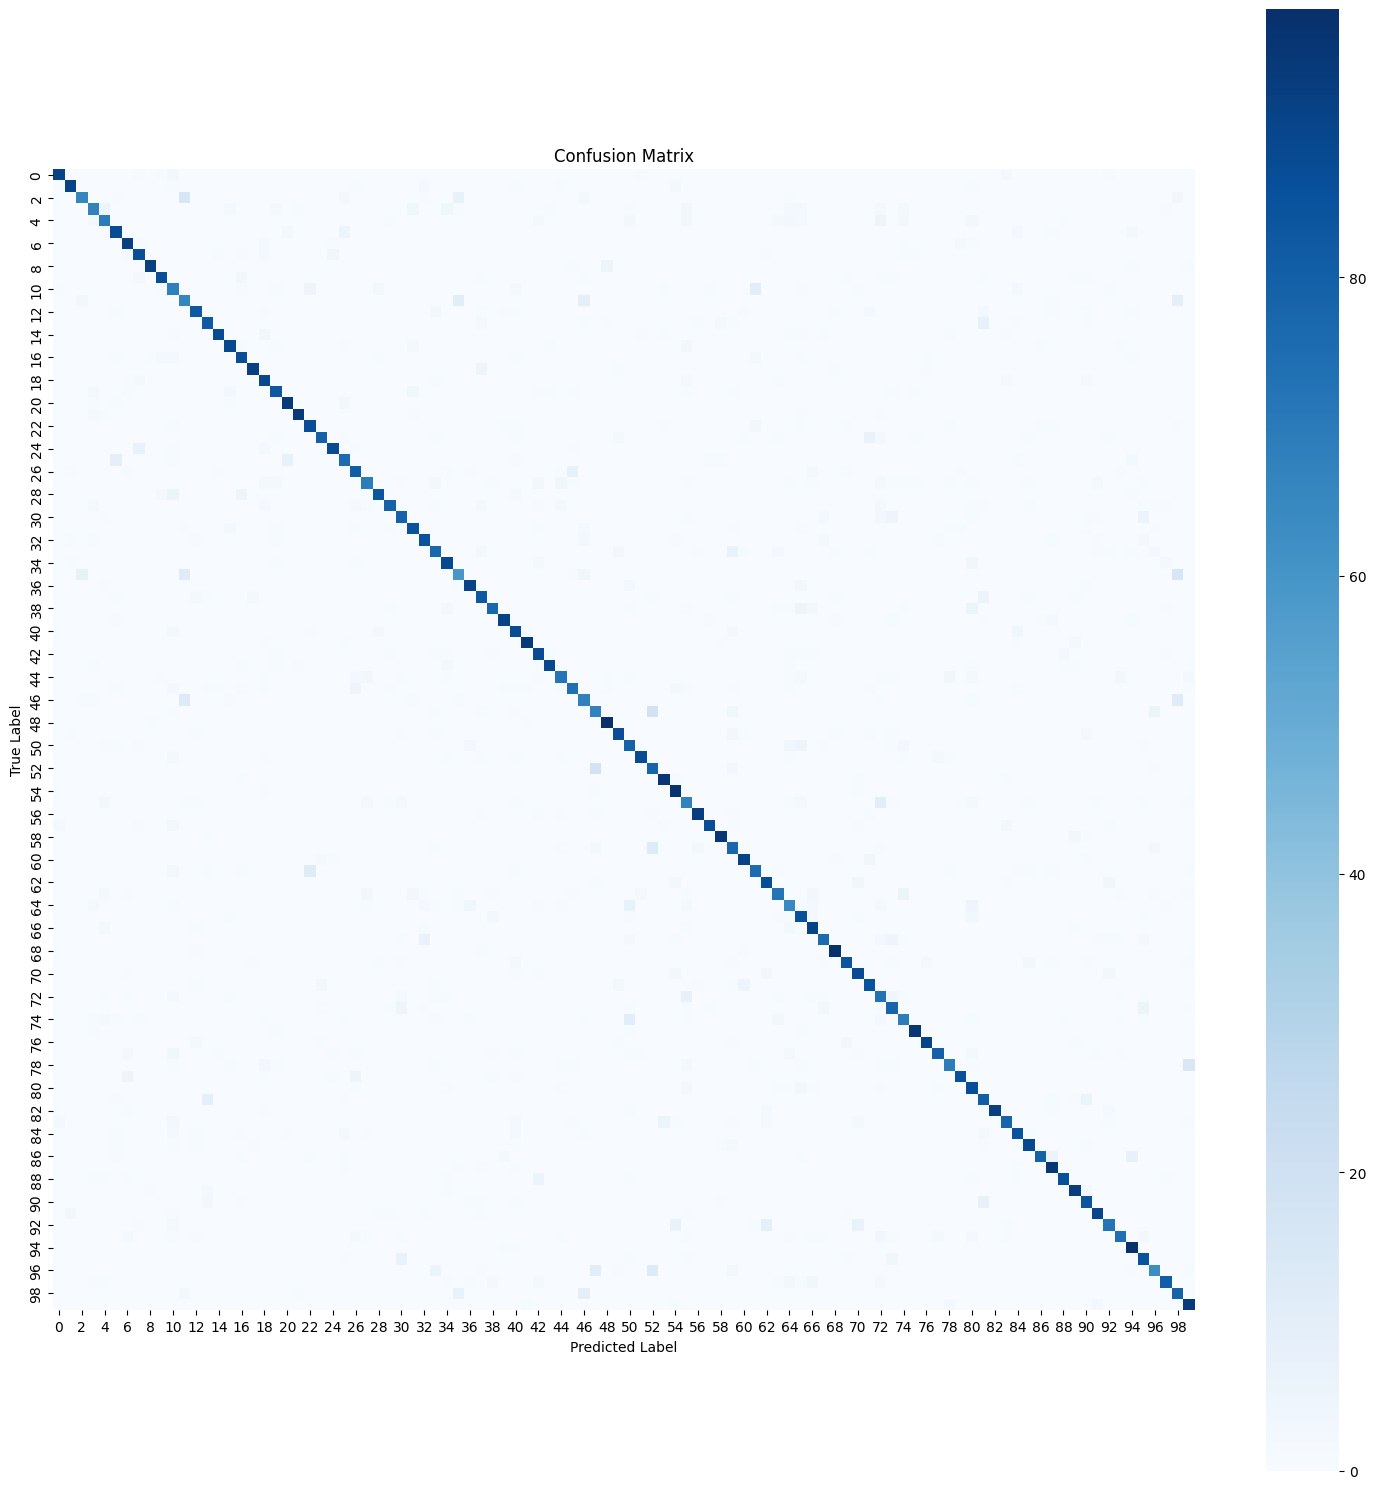

In [4]:
# ===========================
# CELL 2 : TESTING
# ===========================

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load best model
model = HybridEva02_DCNN(CONFIG['model_name'], CONFIG['num_classes']).to(CONFIG['device'])
model.load_state_dict(torch.load(CONFIG['checkpoint_path'], map_location=CONFIG['device']))
model.eval()

# Get test loader
_, test_loader = get_dataloaders(CONFIG['data_dir'])

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(CONFIG['device'])
        labels = labels.to(CONFIG['device'])

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# Accuracy
acc = accuracy_score(y_true, y_pred)
print(f"\nTest Accuracy : {acc*100:.2f}%")

# Classification Report
print("\nClassification Report\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=test_loader.dataset.classes,
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15,15))
sns.heatmap(
    cm,
    cmap="Blues",
    square=True,
    cbar=True
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()